## Model Building & Evaluation

### Import Libraries and Load Cleaned Data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)


# models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# utility functions
from utils import evaluate_model, plot_confusion_matrix, plot_roc_curves, compare_models

sns.set_theme(style="whitegrid")
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [4]:
# import cleaned dataset from from notebook 2
data = pd.read_csv("Data/titanic_cleaned.csv")
print("Data Shape:", data.shape)
data.head(10)

Data Shape: (891, 23)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
0,0,3,0,22.0,1,0,7.2500,0,2,0,...,1,0,0,0,1,0,0,0,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,...,0,1,0,0,0,1,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,1,1,...,0,0,0,0,1,0,0,1,0,0
3,1,1,1,35.0,1,0,53.1000,1,2,0,...,0,1,0,0,1,0,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,1,1,...,1,0,0,0,1,0,0,1,0,0
5,0,3,0,25.0,0,0,8.4583,0,1,1,...,1,0,0,0,1,0,0,1,0,0
6,0,1,0,54.0,0,0,51.8625,1,1,1,...,1,0,0,0,0,1,0,0,0,1
7,0,3,0,2.0,3,1,21.0750,0,5,0,...,0,0,0,0,0,0,0,0,1,0
8,1,3,1,27.0,0,2,11.1333,0,3,0,...,0,1,0,0,1,0,0,1,0,0
9,1,2,1,14.0,1,0,30.0708,0,2,0,...,0,1,0,1,0,0,0,0,1,0


### Prepare Features and Target

In [5]:
# seprate features and taget
X = data.drop(columns=["Survived"])
y = data["Survived"]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"\nFeature columns: {X.columns.tolist()}")

Features shape: (891, 22)
Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Feature columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeGroup_Teen', 'AgeGroup_Young Adult', 'AgeGroup_Adult', 'AgeGroup_Senior', 'FareBin_Medium', 'FareBin_High', 'FareBin_Very High']


In [6]:
# Train/test split (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y) 


print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nTraining survival rate: {y_train.mean():.2%}")
print(f"Test survival rate: {y_test.mean():.2%}")

Training set: 623 samples
Test set: 268 samples

Training survival rate: 38.36%
Test survival rate: 38.43%


In [7]:
# Feature scaling — important for KNN, SVM, and Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Scaling complete. First 3 rows of scaled training data:")
X_train_scaled.head(3)

Scaling complete. First 3 rows of scaled training data:


,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_Q,...,Title_Mr,Title_Mrs,Title_Rare,AgeGroup_Teen,AgeGroup_Young Adult,AgeGroup_Adult,AgeGroup_Senior,FareBin_Medium,FareBin_High,FareBin_Very High
748,-1.589202,-0.731083,-0.782506,0.562957,-0.448665,0.465738,1.892322,0.110685,-1.284937,-0.304930,...,0.843527,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,-0.590326,-0.577968,1.815641
45,0.819734,-0.731083,-0.332603,-0.474682,-0.448665,-0.478269,-0.528451,-0.558800,0.778248,-0.304930,...,0.843527,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,1.693979,-0.577968,-0.550770
28,0.819734,1.367833,-0.595047,-0.474682,-0.448665,-0.481848,-0.528451,-0.558800,0.778248,3.279439,...,-1.185498,-0.413585,-0.182119,-0.279024,0.871715,-0.595271,-0.15707,-0.590326,-0.577968,-0.550770


### Train Models

In [8]:
# Store results for comparison
results = []
trained_models = {}

#### Logistic Regression


  Logistic Regression Results
  Accuracy:  0.8396
  Precision: 0.7778
  Recall:    0.8155
  F1 Score:  0.7962

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.87       165
           1       0.78      0.82      0.80       103

    accuracy                           0.84       268
   macro avg       0.83      0.84      0.83       268
weighted avg       0.84      0.84      0.84       268



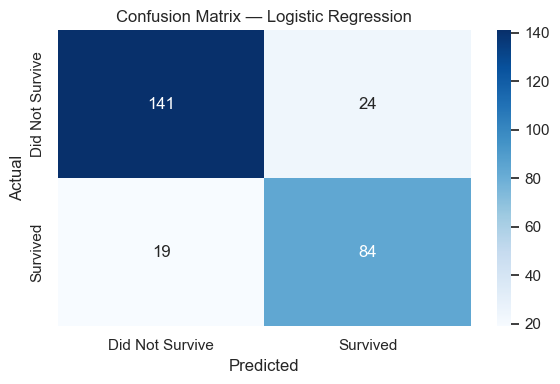

In [9]:
lr = LogisticRegression(random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
metrics_lr = evaluate_model(y_test, y_pred_lr, "Logistic Regression")
results.append(metrics_lr)
trained_models["Logistic Regression"] = lr

plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")

#### Decision Tree


  Decision Tree Results
  Accuracy:  0.8172
  Precision: 0.7288
  Recall:    0.8350
  F1 Score:  0.7783

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.84       165
           1       0.73      0.83      0.78       103

    accuracy                           0.82       268
   macro avg       0.81      0.82      0.81       268
weighted avg       0.83      0.82      0.82       268



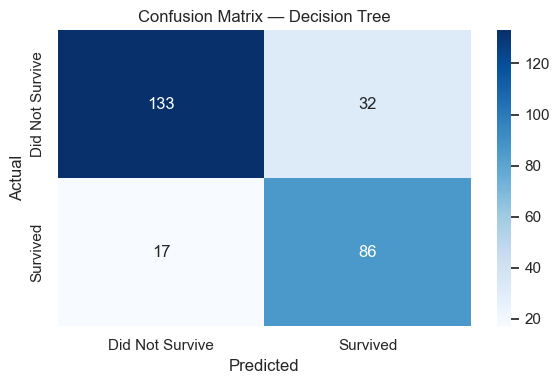

In [10]:
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
metrics_dt = evaluate_model(y_test, y_pred_dt, "Decision Tree")
results.append(metrics_dt)
trained_models["Decision Tree"] = dt

plot_confusion_matrix(y_test, y_pred_dt, "Decision Tree")

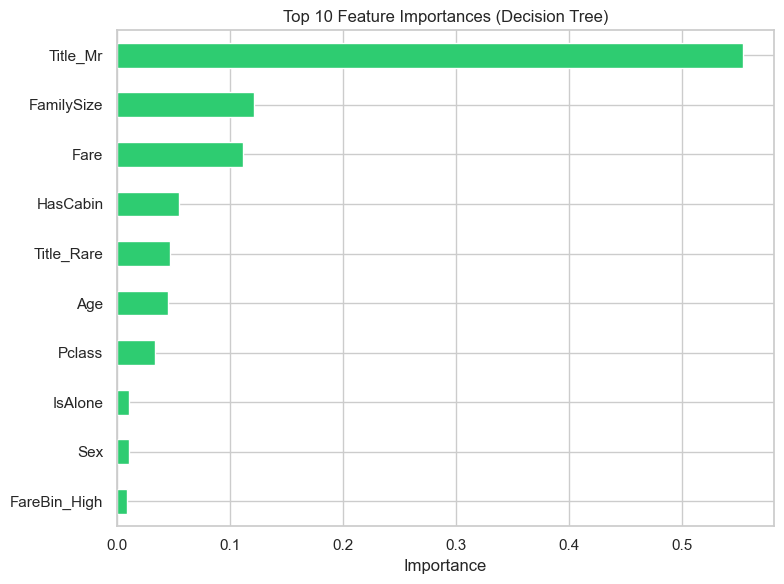

In [12]:
# Feature importance from Decision Tree
feature_imp = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8,6))
feature_imp.tail(10).plot(kind="barh", ax=ax, color="#2ecc71")
ax.set_title("Top 10 Feature Importances (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### Random Forest


  Random Forest Results
  Accuracy:  0.8022
  Precision: 0.7841
  Recall:    0.6699
  F1 Score:  0.7225

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.67      0.72       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.78       268
weighted avg       0.80      0.80      0.80       268



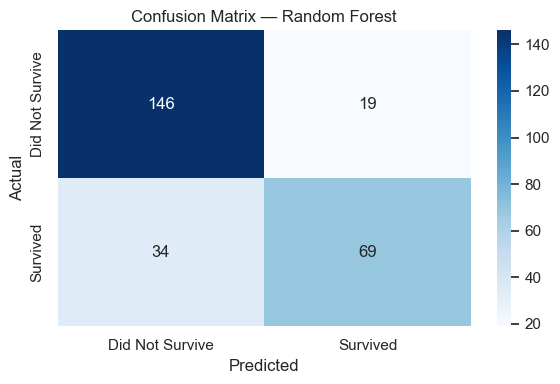

In [13]:
rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=7)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
metrics_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
results.append(metrics_rf)
trained_models["Random Forest"] = rf

plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")

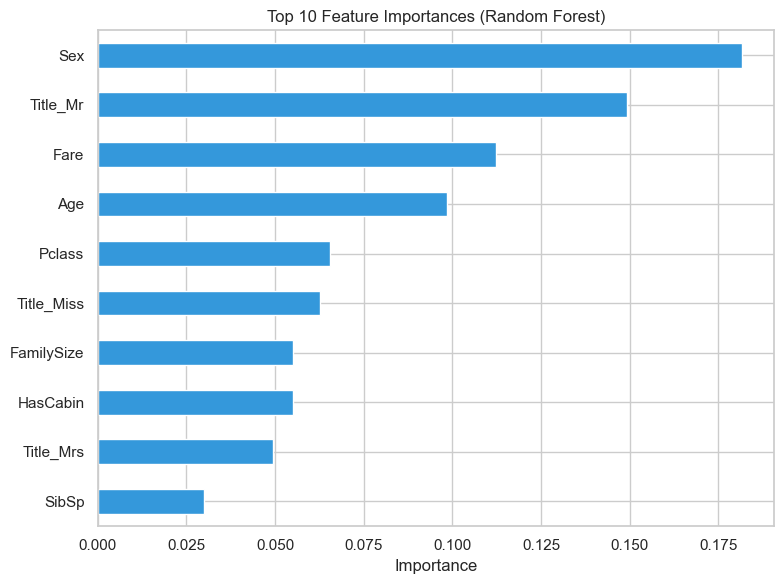

In [14]:
# Feature importance from Random Forest
feature_imp_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_imp_rf = feature_imp_rf.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp_rf.tail(10).plot(kind="barh", ax=ax, color="#3498db")
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


  K-Nearest Neighbors Results
  Accuracy:  0.7724
  Precision: 0.7500
  Recall:    0.6117
  F1 Score:  0.6738

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.83       165
           1       0.75      0.61      0.67       103

    accuracy                           0.77       268
   macro avg       0.77      0.74      0.75       268
weighted avg       0.77      0.77      0.77       268



  File "C:\Users\Manoj Shah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^

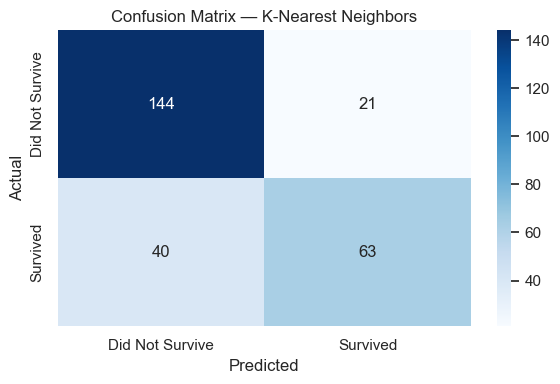

In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
metrics_knn = evaluate_model(y_test, y_pred_knn, "K-Nearest Neighbors")
results.append(metrics_knn)
trained_models["K-Nearest Neighbors"] = knn

plot_confusion_matrix(y_test, y_pred_knn, "K-Nearest Neighbors")

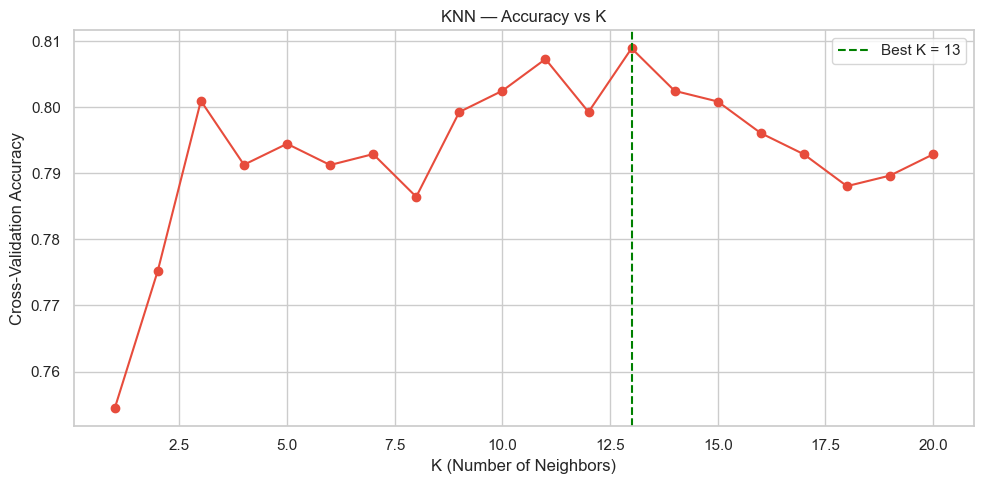

Best K: 13 with accuracy: 0.8089


In [16]:
# Find optimal K using cross-validation
k_range = range(1, 21)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy")
    k_scores.append(scores.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, marker="o", color="#e74c3c")
ax.set_title("KNN — Accuracy vs K")
ax.set_xlabel("K (Number of Neighbors)")
ax.set_ylabel("Cross-Validation Accuracy")
best_k = list(k_range)[np.argmax(k_scores)]
ax.axvline(x=best_k, color="green", linestyle="--", label=f"Best K = {best_k}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Best K: {best_k} with accuracy: {max(k_scores):.4f}")

#### Support Vector Machine (SVM)


  Support Vector Machine Results
  Accuracy:  0.8134
  Precision: 0.7789
  Recall:    0.7184
  F1 Score:  0.7475

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       165
           1       0.78      0.72      0.75       103

    accuracy                           0.81       268
   macro avg       0.81      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268



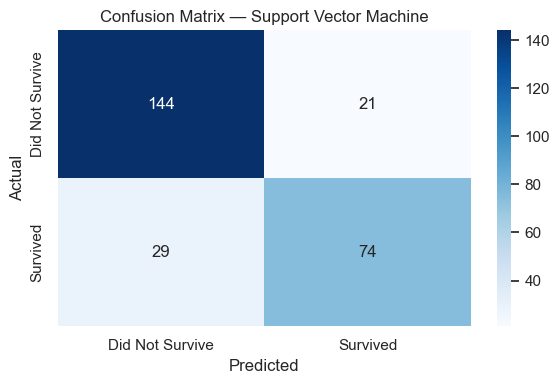

In [17]:
svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
metrics_svm = evaluate_model(y_test, y_pred_svm, "Support Vector Machine")
results.append(metrics_svm)
trained_models["Support Vector Machine"] = svm

plot_confusion_matrix(y_test, y_pred_svm, "Support Vector Machine")

#### Gradient Boosting


  Gradient Boosting Results
  Accuracy:  0.8060
  Precision: 0.7931
  Recall:    0.6699
  F1 Score:  0.7263

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       165
           1       0.79      0.67      0.73       103

    accuracy                           0.81       268
   macro avg       0.80      0.78      0.79       268
weighted avg       0.80      0.81      0.80       268



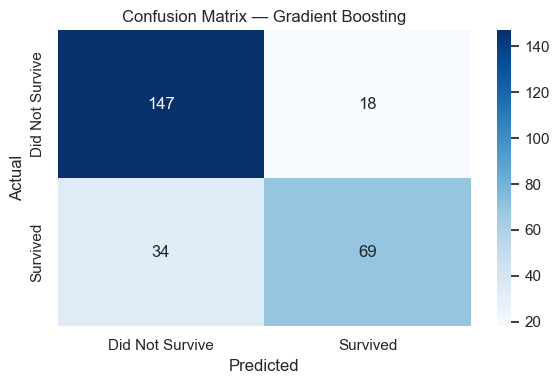

In [18]:
gb = GradientBoostingClassifier(random_state=42, n_estimators=100, learning_rate=0.1, max_depth=3)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
metrics_gb = evaluate_model(y_test, y_pred_gb, "Gradient Boosting")
results.append(metrics_gb)
trained_models["Gradient Boosting"] = gb

plot_confusion_matrix(y_test, y_pred_gb, "Gradient Boosting")

#### Gaussian Naive Bayes


  Naive Bayes Results
  Accuracy:  0.7873
  Precision: 0.6949
  Recall:    0.7961
  F1 Score:  0.7421

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       165
           1       0.69      0.80      0.74       103

    accuracy                           0.79       268
   macro avg       0.78      0.79      0.78       268
weighted avg       0.80      0.79      0.79       268



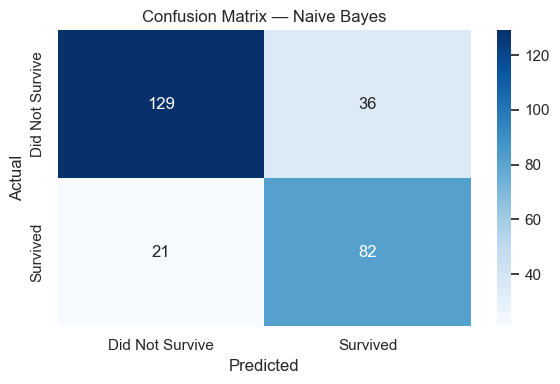

In [19]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
metrics_nb = evaluate_model(y_test, y_pred_nb, "Naive Bayes")
results.append(metrics_nb)
trained_models["Naive Bayes"] = nb

plot_confusion_matrix(y_test, y_pred_nb, "Naive Bayes")